# Task 1 — BERT Baseline for Music Tag Understanding
CSE425/EEE474/CSE715 — GNN-Based BERT for Understanding Context from Music

**Dataset:** MagnaTagATune (top-50 tags), loaded from:
```
E:\CSE715\Datasets\MagnaTagATune\annotations_final.csv
E:\CSE715\Datasets\MagnaTagATune\MagnaTagATune\0..f\*.mp3
```

**Model:**
$$ t = BERT_{CLS}(X_{text}), \qquad \hat{y}_k = \sigma(w_k^\top t + b_k) $$

**Loss:**
$$ \mathcal{L}_{BERT} = -\frac{1}{K}\sum_{k=1}^{K}\Big[y_k \log \hat{y}_k + (1-y_k)\log(1-\hat{y}_k)\Big] $$

**Important design note (read before running):** MagnaTagATune has no natural-language captions/lyrics — the only "text" available is the tag annotations themselves, which are also the prediction target. Feeding a clip's full tag list into BERT and asking it to predict those same tags back would be circular/trivial. This notebook instead **reveals a random subset (30-60%) of a clip's true tags** as a pseudo-caption (e.g. *"This track is tagged with: guitar, fast, distortion."*) and trains BERT to predict the **full top-50 tag vector**. This keeps every equation/Algorithm in the brief unchanged while making the task genuinely learnable (not circular), since the target always includes tags the model wasn't told about. If you'd rather use real captions, swap in MusicCaps later — only the `build_pseudo_caption` function below needs to change.

**Official split used** (Dieleman & Schrauwen convention, referenced in the brief as "official splits"): train = folders `0-9,a,b`, val = folder `c`, test = folders `d,e,f` (based on the leading folder letter in `mp3_path`).

## 0. Setup & Configuration

In [18]:
# If needed: !pip install torch transformers pandas numpy scikit-learn tqdm matplotlib

import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import average_precision_score, f1_score, precision_recall_fscore_support

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [19]:
CONFIG = {
    # --- your dataset location ---
    'annotations_csv': r'E:\CSE715\Datasets\MagnaTagATune\annotations_final.csv',
    'audio_root':      r'E:\CSE715\Datasets\MagnaTagATune\MagnaTagATune',

    # --- output locations (created under your working directory) ---
    'processed_dir': r'E:\CSE715\Task_1\data\processed',
    'splits_dir':    r'E:\CSE715\Task_1\data\splits',
    'checkpoint_dir': r'E:\CSE715\Task_1\results\checkpoints',
    'plots_dir':     r'E:\CSE715\Task_1\results\plots',
    'metrics_path':  r'E:\CSE715\Task_1\results\metrics.json',

    # --- data / labeling ---
    'top_k_tags': 50,
    'min_reveal_ratio': 0.3,
    'max_reveal_ratio': 0.6,
    'min_positive_tags': 1,
    'seed': 42,

    # --- model ---
    'model_name': 'distilbert-base-uncased',
    'max_length': 128,
    'dropout': 0.1,

    # --- training ---
    'batch_size': 32,
    'epochs': 25,
    'learning_rate': 2e-5,
    'weight_decay': 0.01,
    'warmup_ratio': 0.06,
    'fp16': True,
    'num_workers': 0,          # 0 is safest inside notebooks on Windows
    'grad_clip_norm': 1.0,
    'num_example_predictions': 5,
}

for d in [CONFIG['processed_dir'], CONFIG['splits_dir'], CONFIG['checkpoint_dir'], CONFIG['plots_dir']]:
    os.makedirs(d, exist_ok=True)

print('Config ready.')

Config ready.


## 1. Load & Preprocess Data
Load `annotations_final.csv`, pick the top-50 most frequent tags, filter clips with no positive tag among them, and tag each clip with its official split folder.

In [20]:
def load_annotations(csv_path):
    df = pd.read_csv(csv_path, sep='\t')
    df.columns = [c.strip() for c in df.columns]
    if 'clip_id' not in df.columns or 'mp3_path' not in df.columns:
        raise ValueError(f'Unexpected columns: {list(df.columns)[:5]}...')
    return df

def get_top_k_tags(df, k):
    non_tag_cols = {'clip_id', 'mp3_path'}
    tag_cols = [c for c in df.columns if c not in non_tag_cols]
    counts = df[tag_cols].sum(axis=0).sort_values(ascending=False)
    return counts.head(k).index.tolist()

def filter_clips(df, tag_cols, min_positive=1):
    mask = df[tag_cols].sum(axis=1) >= min_positive
    return df.loc[mask].reset_index(drop=True)

def attach_split_folder(df):
    def leading_folder(path):
        path = str(path).replace('\\\\', '/').replace('\\', '/')
        return path.split('/')[0].strip().lower()
    df = df.copy()
    df['split_folder'] = df['mp3_path'].apply(leading_folder)
    return df

raw_df = load_annotations(CONFIG['annotations_csv'])
tag_cols = get_top_k_tags(raw_df, CONFIG['top_k_tags'])
df = filter_clips(raw_df, tag_cols, CONFIG['min_positive_tags'])
df = attach_split_folder(df)
df = df[['clip_id', 'mp3_path', 'split_folder'] + tag_cols]

print(f'Total usable clips: {len(df)}')
print(f'Number of tags: {len(tag_cols)}')
print('Top 10 tags by frequency:', tag_cols[:10])
df.head()

Total usable clips: 21111
Number of tags: 50
Top 10 tags by frequency: ['guitar', 'classical', 'slow', 'techno', 'strings', 'drums', 'electronic', 'rock', 'fast', 'piano']


,clip_id,mp3_path,split_folder,guitar,classical,slow,techno,strings,drums,electronic,...,male voice,beats,harp,cello,no voice,weird,country,metal,female voice,choral
0,2,f/american_bach_soloists-j_s__bach_solo_cantat...,f,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,6,f/american_bach_soloists-j_s__bach_solo_cantat...,f,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,10,f/american_bach_soloists-j_s__bach_solo_cantat...,f,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,11,f/american_bach_soloists-j_s__bach_solo_cantat...,f,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12,f/american_bach_soloists-j_s__bach_solo_cantat...,f,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


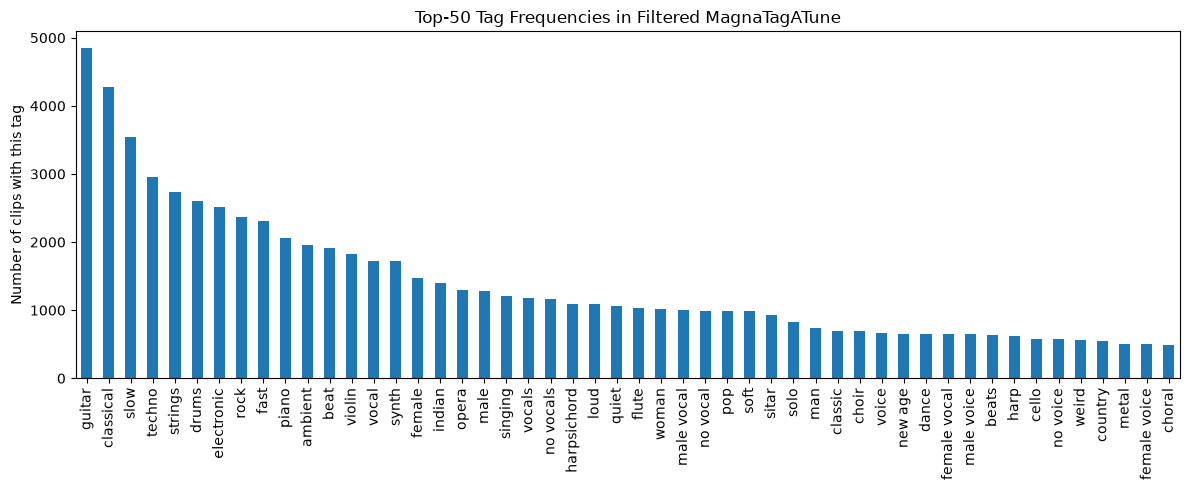

split_folder
0     914
1    1260
2    1250
3    1024
4    1953
5    1269
6    1491
7     933
8     907
9    1467
a    1148
b    1634
c    1529
d    1339
e    1270
f    1723
Name: count, dtype: int64


In [21]:
# Quick EDA: tag frequency distribution & class imbalance
tag_counts = df[tag_cols].sum(axis=0).sort_values(ascending=False)
plt.figure(figsize=(12, 5))
tag_counts.plot(kind='bar')
plt.title('Top-50 Tag Frequencies in Filtered MagnaTagATune')
plt.ylabel('Number of clips with this tag')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print(df['split_folder'].value_counts().sort_index())

## 2. Official Train/Val/Test Split
`train = 0-9,a,b` | `val = c` | `test = d,e,f`

In [22]:
TRAIN_FOLDERS = set(list('0123456789ab'))
VAL_FOLDERS = {'c'}
TEST_FOLDERS = {'d', 'e', 'f'}

train_df = df[df['split_folder'].isin(TRAIN_FOLDERS)].reset_index(drop=True)
val_df   = df[df['split_folder'].isin(VAL_FOLDERS)].reset_index(drop=True)
test_df  = df[df['split_folder'].isin(TEST_FOLDERS)].reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')

# Save split clip_ids for reproducibility / reuse in evaluate step
for name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    with open(os.path.join(CONFIG['splits_dir'], f'{name}.json'), 'w') as f:
        json.dump(split_df['clip_id'].tolist(), f)
print('Splits saved.')

Train: 15250 | Val: 1529 | Test: 4332
Splits saved.


## 3. Pseudo-Caption Construction & PyTorch Dataset

In [23]:
def get_positive_tags_for_row(row, tag_cols):
    return [t for t in tag_cols if row[t] == 1]

def build_pseudo_caption(positive_tags, reveal_ratio, rng):
    if len(positive_tags) == 0:
        return 'no tags available for this track.', []
    n_reveal = max(1, int(round(len(positive_tags) * reveal_ratio)))
    n_reveal = min(n_reveal, len(positive_tags))
    revealed = rng.sample(positive_tags, n_reveal)
    tag_str = ', '.join(sorted(revealed))
    caption = f'This track is tagged with: {tag_str}.'
    return caption, revealed


class MagnaTagATuneTagDataset(Dataset):
    def __init__(self, df, tag_cols, tokenizer, max_length=128,
                 min_reveal_ratio=0.3, max_reveal_ratio=0.6,
                 base_seed=42, deterministic=False):
        self.df = df.reset_index(drop=True)
        self.tag_cols = tag_cols
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.min_reveal_ratio = min_reveal_ratio
        self.max_reveal_ratio = max_reveal_ratio
        self.base_seed = base_seed
        self.deterministic = deterministic
        self._epoch = 0

    def __len__(self):
        return len(self.df)

    def set_epoch(self, epoch):
        self._epoch = epoch

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        positive_tags = get_positive_tags_for_row(row, self.tag_cols)

        if self.deterministic:
            seed = self.base_seed + int(row['clip_id'])
        else:
            seed = self.base_seed + int(row['clip_id']) * 1000 + self._epoch

        rng = random.Random(seed)
        reveal_ratio = rng.uniform(self.min_reveal_ratio, self.max_reveal_ratio)
        caption, _ = build_pseudo_caption(positive_tags, reveal_ratio, rng)

        encoding = self.tokenizer(
            caption, padding='max_length', truncation=True,
            max_length=self.max_length, return_tensors='pt',
        )
        labels = torch.tensor(row[self.tag_cols].values.astype(np.float32))

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': labels,
            'text': caption,
            'clip_id': int(row['clip_id']),
        }


# Preview a few pseudo-captions
_rng = random.Random(42)
for _, row in df.sample(3, random_state=42).iterrows():
    pos_tags = get_positive_tags_for_row(row, tag_cols)
    cap, revealed = build_pseudo_caption(pos_tags, 0.5, _rng)
    print(f"Clip {row['clip_id']}: true={pos_tags} -> revealed={revealed}\n  caption: {cap}\n")

Clip 23676: true=['guitar', 'rock', 'loud'] -> revealed=['loud', 'guitar']
  caption: This track is tagged with: guitar, loud.

Clip 4607: true=['violin'] -> revealed=['violin']
  caption: This track is tagged with: violin.

Clip 44748: true=['drums', 'electronic'] -> revealed=['electronic']
  caption: This track is tagged with: electronic.



## 4. Build DataLoaders

In [24]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG['model_name'])

train_dataset = MagnaTagATuneTagDataset(
    train_df, tag_cols, tokenizer, max_length=CONFIG['max_length'],
    min_reveal_ratio=CONFIG['min_reveal_ratio'], max_reveal_ratio=CONFIG['max_reveal_ratio'],
    base_seed=CONFIG['seed'], deterministic=False,
)
val_dataset = MagnaTagATuneTagDataset(
    val_df, tag_cols, tokenizer, max_length=CONFIG['max_length'],
    min_reveal_ratio=CONFIG['min_reveal_ratio'], max_reveal_ratio=CONFIG['max_reveal_ratio'],
    base_seed=CONFIG['seed'], deterministic=True,
)
test_dataset = MagnaTagATuneTagDataset(
    test_df, tag_cols, tokenizer, max_length=CONFIG['max_length'],
    min_reveal_ratio=CONFIG['min_reveal_ratio'], max_reveal_ratio=CONFIG['max_reveal_ratio'],
    base_seed=CONFIG['seed'], deterministic=True,
)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], shuffle=True, num_workers=CONFIG['num_workers'])
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')

Train batches: 477 | Val batches: 48 | Test batches: 136


## 5. Model — BERT + Multi-Label Classification Head
$$ t = BERT_{CLS}(X_{text}), \qquad \hat{y}_k = \sigma(w_k^\top t + b_k) $$

In [25]:
class BertTagClassifier(nn.Module):
    def __init__(self, model_name, num_tags, dropout=0.1):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)
        hidden_size = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_tags)

    def forward(self, input_ids, attention_mask):
        outputs = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        if hasattr(outputs, 'pooler_output') and outputs.pooler_output is not None:
            cls_repr = outputs.pooler_output
        else:
            cls_repr = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        cls_repr = self.dropout(cls_repr)
        return self.classifier(cls_repr)

model = BertTagClassifier(CONFIG['model_name'], num_tags=len(tag_cols), dropout=CONFIG['dropout']).to(device)
print(model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 50027.48it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertTagClassifier(
  (backbone): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
            (lin1): 

## 6. Metrics Helper
Precision / Recall / F1 per tag, Macro-F1, Micro-F1, AUC-PR — exactly as defined in the brief.

In [34]:
def compute_metrics(y_true, y_pred_probs, threshold=0.5):
    """threshold can be a scalar OR a length-K array of per-tag thresholds."""
    if np.isscalar(threshold):
        y_pred = (y_pred_probs >= threshold).astype(int)
    else:
        threshold = np.asarray(threshold).reshape(1, -1)
        y_pred = (y_pred_probs >= threshold).astype(int)

    precision_k, recall_k, f1_k, _ = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    macro_f1 = float(np.mean(f1_k))
    micro_f1 = float(f1_score(y_true, y_pred, average='micro', zero_division=0))

    auc_pr_list = []
    for k in range(y_true.shape[1]):
        if y_true[:, k].sum() > 0:
            auc_pr_list.append(average_precision_score(y_true[:, k], y_pred_probs[:, k]))
    mean_auc_pr = float(np.mean(auc_pr_list)) if auc_pr_list else 0.0

    return {
        'macro_f1': macro_f1, 'micro_f1': micro_f1, 'mean_auc_pr': mean_auc_pr,
        'per_tag_precision': precision_k.tolist(), 'per_tag_recall': recall_k.tolist(), 'per_tag_f1': f1_k.tolist(),
    }

def tune_per_tag_thresholds(y_true_val, y_pred_probs_val, grid=np.arange(0.05, 0.96, 0.05)):
    """For each tag, pick the threshold (from `grid`) that maximizes that tag's F1 on validation data."""
    K = y_true_val.shape[1]
    best_thresholds = np.full(K, 0.5)
    for k in range(K):
        if y_true_val[:, k].sum() == 0:
            continue
        best_f1, best_t = -1.0, 0.5
        for t in grid:
            pred_k = (y_pred_probs_val[:, k] >= t).astype(int)
            f1 = f1_score(y_true_val[:, k], pred_k, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        best_thresholds[k] = best_t
    return best_thresholds

@torch.no_grad()
def run_eval(model, loader, device):
    model.eval()
    all_probs, all_labels = [], []
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        logits = model(input_ids, attention_mask)
        probs = torch.sigmoid(logits)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    return compute_metrics(np.concatenate(all_labels), np.concatenate(all_probs))

## 7. Training Loop (Algorithm 1 from the brief)
```
Require: Tag corpus D, pretrained BERT, learning rate eta, epochs E
1. Add classification head W, b on top of CLS token
2. for epoch = 1 to E:
3.     for each mini-batch in D:
4.         t <- BERT_CLS(X_text)
5.         y_hat <- sigmoid(Wt + b)
6.         L <- BCE(y, y_hat)
7.         Update BERT (optional) and head via eta * grad(L)
8. return fine-tuned BERT tag model
```

In [35]:
optimizer = AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
criterion = nn.BCEWithLogitsLoss()

total_steps = len(train_loader) * CONFIG['epochs']
warmup_steps = int(CONFIG['warmup_ratio'] * total_steps)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

use_amp = CONFIG['fp16'] and device.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

history = {'epoch': [], 'train_loss': [], 'val_macro_f1': [], 'val_micro_f1': [], 'val_auc_pr': []}
best_macro_f1 = -1.0
best_ckpt_path = os.path.join(CONFIG['checkpoint_dir'], 'best_model.pt')

for epoch in range(1, CONFIG['epochs'] + 1):
    model.train()
    train_dataset.set_epoch(epoch)
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f'Epoch {epoch}/{CONFIG["epochs"]}')
    for step, batch in enumerate(pbar):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip_norm'])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item()
        pbar.set_postfix(loss=running_loss / (step + 1))

    avg_train_loss = running_loss / len(train_loader)
    val_metrics = run_eval(model, val_loader, device)

    print(f"[Epoch {epoch}] train_loss={avg_train_loss:.4f} val_macro_f1={val_metrics['macro_f1']:.4f} "
          f"val_micro_f1={val_metrics['micro_f1']:.4f} val_auc_pr={val_metrics['mean_auc_pr']:.4f}")

    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['val_macro_f1'].append(val_metrics['macro_f1'])
    history['val_micro_f1'].append(val_metrics['micro_f1'])
    history['val_auc_pr'].append(val_metrics['mean_auc_pr'])

    if val_metrics['macro_f1'] > best_macro_f1:
        best_macro_f1 = val_metrics['macro_f1']
        torch.save({'model_state_dict': model.state_dict(), 'tag_cols': tag_cols,
                    'config': CONFIG, 'epoch': epoch, 'val_macro_f1': best_macro_f1}, best_ckpt_path)
        print(f'  -> New best model saved (val_macro_f1={best_macro_f1:.4f})')

with open(os.path.join(CONFIG['checkpoint_dir'], 'history.json'), 'w') as f:
    json.dump(history, f, indent=2)

print(f"\nTraining complete. Best val Macro-F1: {best_macro_f1:.4f}")

C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
Epoch 1/25:   0%|          | 0/477 [00:00<?, ?it/s]C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 1/25: 100%|██████████| 477/477 [00:38<00:00, 12.49it/s, loss=0.101] 


[Epoch 1] train_loss=0.1006 val_macro_f1=0.6840 val_micro_f1=0.7206 val_auc_pr=0.7388
  -> New best model saved (val_macro_f1=0.6840)


Epoch 2/25:   0%|          | 0/477 [00:00<?, ?it/s]C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 2/25: 100%|██████████| 477/477 [00:37<00:00, 12.60it/s, loss=0.101] 


[Epoch 2] train_loss=0.1014 val_macro_f1=0.6763 val_micro_f1=0.7154 val_auc_pr=0.7376


Epoch 3/25:   0%|          | 0/477 [00:00<?, ?it/s]C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 3/25: 100%|██████████| 477/477 [00:37<00:00, 12.64it/s, loss=0.101] 


...

[Epoch 23] train_loss=0.0972 val_macro_f1=0.6806 val_micro_f1=0.7168 val_auc_pr=0.7415


Epoch 24/25:   0%|          | 0/477 [00:00<?, ?it/s]C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 24/25: 100%|██████████| 477/477 [00:38<00:00, 12.47it/s, loss=0.0973]


[Epoch 24] train_loss=0.0973 val_macro_f1=0.6817 val_micro_f1=0.7168 val_auc_pr=0.7415


Epoch 25/25:   0%|          | 0/477 [00:00<?, ?it/s]C:\Users\user3\AppData\Local\Temp\ipykernel_17676\797186189.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
Epoch 25/25: 100%|██████████| 477/477 [00:38<00:00, 12.53it/s, loss=0.0971]


[Epoch 25] train_loss=0.0971 val_macro_f1=0.6817 val_micro_f1=0.7170 val_auc_pr=0.7416

Training complete. Best val Macro-F1: 0.6875


## 8. Macro-F1 / Micro-F1 Curves vs. Epoch (deliverable)

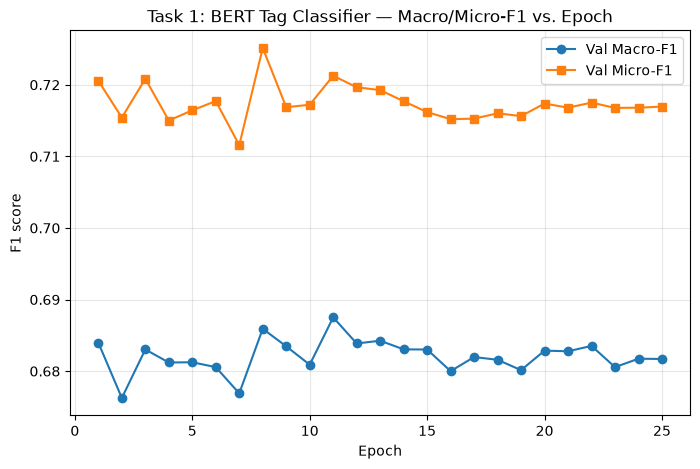

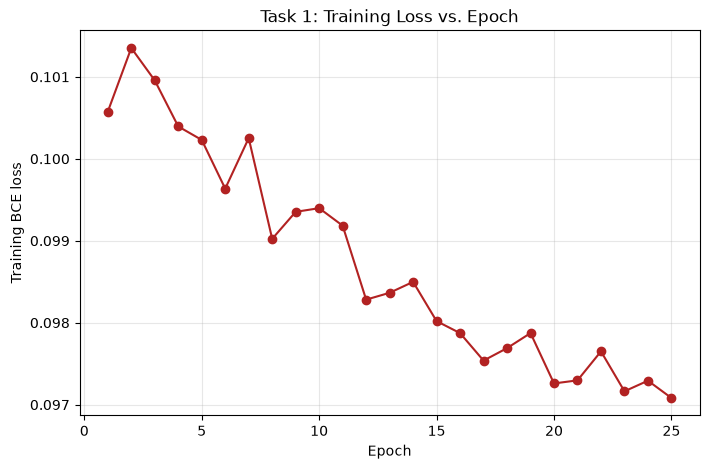

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(history['epoch'], history['val_macro_f1'], marker='o', label='Val Macro-F1')
plt.plot(history['epoch'], history['val_micro_f1'], marker='s', label='Val Micro-F1')
plt.xlabel('Epoch'); plt.ylabel('F1 score')
plt.title('Task 1: BERT Tag Classifier — Macro/Micro-F1 vs. Epoch')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(os.path.join(CONFIG['plots_dir'], 'f1_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history['epoch'], history['train_loss'], marker='o', color='firebrick')
plt.xlabel('Epoch'); plt.ylabel('Training BCE loss')
plt.title('Task 1: Training Loss vs. Epoch')
plt.grid(alpha=0.3)
plt.savefig(os.path.join(CONFIG['plots_dir'], 'loss_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## 9. Test Set Evaluation + Baseline Comparison

In [37]:
def majority_baseline_metrics(train_labels, test_labels):
    tag_freq = train_labels.mean(axis=0)  # (K,) marginal probability per tag
    y_pred_probs = np.tile(tag_freq, (test_labels.shape[0], 1))

    # Predict the top-K most frequent tags (K = avg #tags/clip) instead of thresholding at 0.5
    avg_num_tags = max(1, int(round(train_labels.sum(axis=1).mean())))
    sorted_freq = np.sort(tag_freq)[::-1]
    cutoff = sorted_freq[avg_num_tags - 1]
    return compute_metrics(test_labels, y_pred_probs, threshold=cutoff)

def random_baseline_metrics(test_labels, seed=0):
    rng = np.random.RandomState(seed)
    y_pred_probs = rng.rand(*test_labels.shape)
    return compute_metrics(test_labels, y_pred_probs)

@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_probs, all_labels, all_texts, all_ids = [], [], [], []
    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        logits = model(input_ids, attention_mask)
        probs = torch.sigmoid(logits)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
        all_texts.extend(batch['text'])
        all_ids.extend(batch['clip_id'].tolist())
    return np.concatenate(all_probs), np.concatenate(all_labels), all_texts, all_ids

# Load best checkpoint
checkpoint = torch.load(best_ckpt_path, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])

# 1) Get val predictions and tune per-tag thresholds
val_pred_probs, val_true, _, _ = collect_predictions(model, val_loader, device)
best_thresholds = tune_per_tag_thresholds(val_true, val_pred_probs)

# 2) Get test predictions, evaluate at 0.5 (old way) AND with tuned thresholds
y_pred_probs, y_true, texts, clip_ids = collect_predictions(model, test_loader, device)
bert_metrics_default = compute_metrics(y_true, y_pred_probs, threshold=0.5)
bert_metrics = compute_metrics(y_true, y_pred_probs, threshold=best_thresholds)

train_labels = train_df[tag_cols].values.astype(np.float32)
b1_metrics = majority_baseline_metrics(train_labels, y_true)
b_random_metrics = random_baseline_metrics(y_true, seed=CONFIG['seed'])

print('=== Test Set Results ===')
print(f"BERT (threshold=0.5)   -> Macro-F1: {bert_metrics_default['macro_f1']:.4f} | Micro-F1: {bert_metrics_default['micro_f1']:.4f}")
print(f"BERT (tuned thresholds)-> Macro-F1: {bert_metrics['macro_f1']:.4f} | Micro-F1: {bert_metrics['micro_f1']:.4f} | AUC-PR: {bert_metrics['mean_auc_pr']:.4f}")
print(f"B1 (top-K majority)    -> Macro-F1: {b1_metrics['macro_f1']:.4f} | Micro-F1: {b1_metrics['micro_f1']:.4f} | AUC-PR: {b1_metrics['mean_auc_pr']:.4f}")
print(f"B_random               -> Macro-F1: {b_random_metrics['macro_f1']:.4f} | Micro-F1: {b_random_metrics['micro_f1']:.4f} | AUC-PR: {b_random_metrics['mean_auc_pr']:.4f}")

results = {
    'num_tags': len(tag_cols), 'test_size': len(test_df),
    'bert_model_threshold_0.5': {k: bert_metrics_default[k] for k in ['macro_f1', 'micro_f1', 'mean_auc_pr']},
    'bert_model_tuned_thresholds': {k: bert_metrics[k] for k in ['macro_f1', 'micro_f1', 'mean_auc_pr']},
    'baseline_majority_class': {k: b1_metrics[k] for k in ['macro_f1', 'micro_f1', 'mean_auc_pr']},
    'baseline_random': {k: b_random_metrics[k] for k in ['macro_f1', 'micro_f1', 'mean_auc_pr']},
    'per_tag_thresholds': best_thresholds.tolist(),
    'per_tag': {tag: {'precision': bert_metrics['per_tag_precision'][i],
                        'recall': bert_metrics['per_tag_recall'][i],
                        'f1': bert_metrics['per_tag_f1'][i]} for i, tag in enumerate(tag_cols)},
}
with open(CONFIG['metrics_path'], 'w') as f:
    json.dump(results, f, indent=2)
print(f"\nFull metrics saved to {CONFIG['metrics_path']}")

C:\Users\user3\AppData\Local\Temp\ipykernel_17676\1726152969.py:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(best_ckpt_path, map_location=device

=== Test Set Results ===
BERT (threshold=0.5)   -> Macro-F1: 0.6918 | Micro-F1: 0.7101
BERT (tuned thresholds)-> Macro-F1: 0.6758 | Micro-F1: 0.7016 | AUC-PR: 0.7440
B1 (top-K majority)    -> Macro-F1: 0.0186 | Micro-F1: 0.1754 | AUC-PR: 0.0653
B_random               -> Macro-F1: 0.1113 | Micro-F1: 0.1163 | AUC-PR: 0.0672

Full metrics saved to E:\CSE715\Task_1\results\metrics.json


## 10. Example Predictions (deliverable — 5 examples)

In [38]:
rng_np = np.random.RandomState(CONFIG['seed'])
idxs = rng_np.choice(len(texts), size=min(CONFIG['num_example_predictions'], len(texts)), replace=False)

examples = []
for idx in idxs:
    top_k = 5
    pred_probs = y_pred_probs[idx]
    top_indices = np.argsort(-pred_probs)[:top_k]
    predicted_tags = [(tag_cols[i], float(pred_probs[i])) for i in top_indices]
    true_tags = [tag_cols[i] for i in range(len(tag_cols)) if y_true[idx][i] == 1]

    examples.append({'clip_id': clip_ids[idx], 'input_text': texts[idx],
                      'true_tags': true_tags, 'top_predicted_tags': predicted_tags})

    print(f'\nClip {clip_ids[idx]}')
    print(f'  Input text : {texts[idx]}')
    print(f'  True tags  : {true_tags}')
    print(f'  Top-5 pred : {[(t, round(p, 3)) for t, p in predicted_tags]}')

with open(os.path.join(os.path.dirname(CONFIG['metrics_path']), 'example_predictions.json'), 'w') as f:
    json.dump(examples, f, indent=2)


Clip 33136
  Input text : This track is tagged with: drums.
  True tags  : ['drums']
  Top-5 pred : [('drums', 0.997), ('beat', 0.079), ('indian', 0.076), ('rock', 0.071), ('guitar', 0.056)]

Clip 17116
  Input text : This track is tagged with: quiet, techno.
  True tags  : ['techno', 'drums', 'electronic', 'quiet']
  Top-5 pred : [('quiet', 0.982), ('techno', 0.887), ('electronic', 0.496), ('ambient', 0.415), ('slow', 0.353)]

Clip 35716
  Input text : This track is tagged with: piano.
  True tags  : ['slow', 'piano']
  Top-5 pred : [('piano', 0.995), ('classical', 0.252), ('slow', 0.055), ('solo', 0.053), ('fast', 0.043)]

Clip 128
  Input text : This track is tagged with: flute.
  True tags  : ['flute']
  Top-5 pred : [('flute', 0.99), ('classical', 0.208), ('slow', 0.164), ('drums', 0.049), ('ambient', 0.047)]

Clip 51052
  Input text : This track is tagged with: strings.
  True tags  : ['classical', 'strings']
  Top-5 pred : [('strings', 0.997), ('classical', 0.487), ('violin', 0

## 11. End-to-End Inference Demo (custom text)

In [39]:
def predict_tags(text, top_k=10):
    encoding = tokenizer(text, padding='max_length', truncation=True,
                          max_length=CONFIG['max_length'], return_tensors='pt')
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        logits = model(input_ids, attention_mask)
        probs = torch.sigmoid(logits).cpu().numpy()[0]
    top_indices = probs.argsort()[::-1][:top_k]
    return [(tag_cols[i], round(float(probs[i]), 3)) for i in top_indices]

sample_text = 'This track is tagged with: guitar, fast, distortion.'
print(f'Input: "{sample_text}"\n')
for tag, prob in predict_tags(sample_text, top_k=10):
    print(f'  {tag:15s} {prob:.3f}')

Input: "This track is tagged with: guitar, fast, distortion."

  fast            0.993
  guitar          0.987
  rock            0.607
  loud            0.567
  drums           0.362
  no vocal        0.195
  solo            0.160
  slow            0.150
  flute           0.129
  electronic      0.128
